## Distribuição de Exponencial

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import expon
sns.set_theme(style="whitegrid")

Vamos começar simulando o tempo de espera até a chegada do próximo cliente a um caixa eletrônico.

O caixa recebe, em média, 3,6 clientes a cada 10 minutos. Portanto, o tempo médio entre chegadas é de aproximadamente 2,78 minutos.

Vamos utilizar a distribuição Exponencial para gerar tempos de espera aleatórios.

In [2]:
# Taxa média de chegada por minuto
lamb = 3.6 / 10

# Tempo médio de espera
media = 1 / lamb
media

2.7777777777777777

Há um detalhe importante que merece destaque: o NumPy utiliza o parâmetro scale, que corresponde à média da distribuição, e não à taxa λ. Assim, scale = 1/λ.

Vamos gerar um tempo de espera.

In [3]:
np.random.exponential(scale=media)

1.8426554471134544

Agora, vamos gerar 10 tempos de espera.

In [4]:
np.random.exponential(scale=media, size=10)

array([ 3.91512673,  5.38555818,  0.693095  , 10.78444799,  3.64398361,
        4.15179762,  3.62446358,  3.93787594,  0.63217689,  2.2809407 ])

Vamos agora gerar 1.000 tempos de espera e plotar um gráfico mostrando o resultado.

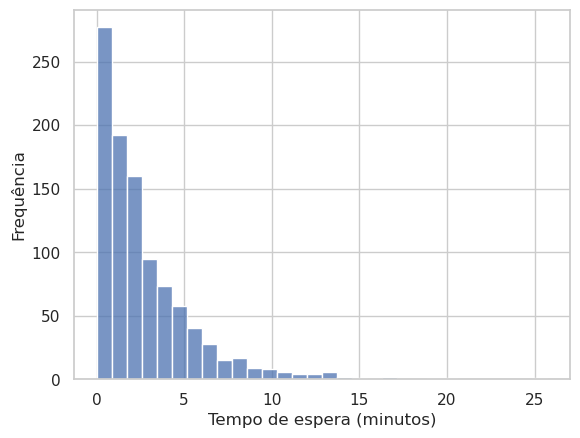

In [5]:
tempos = np.random.exponential(scale=media, size=1000)
sns.histplot(tempos, bins=30)
plt.xlabel("Tempo de espera (minutos)")
plt.ylabel("Frequência")
plt.show()

Um caixa eletrônico recebe, em média, 3,6 clientes a cada 10 minutos. Qual é a probabilidade de que o próximo cliente chegue em menos de 5 minutos?


In [6]:
expon.cdf(5, scale=media)

0.8347011117784134

expon.cdf(k, scale) - Cumulative distribution function - igual ou menos que \
expon.pdf(k, scale) - Probability density function - para o valor exato \
expon.sf(k, scale) - Para mais que (similar a 1 - cdf) \
expon.mean(k, scale) - Para a média da distribuição \
expon.var(k scale) - Para a variância da distribuição \
expon.std(k, scale) - Para o desvio padrão da distribuição

Qual é a probabilidade do tempo de espera ser superior a 5 minutos? 

In [7]:
expon.sf(5, scale=media)

0.16529888822158653

E a probabilidade de que o próximo cliente chegue entre 2 e 5 minutos?

In [8]:
expon.cdf(5, scale=media) - expon.cdf(2, scale=media)

0.3214533677383852

Vejamos agora o cálculo da média, variância e desvio padrão.

In [9]:
expon.mean(scale=media)

2.7777777777777777

In [10]:
expon.var(scale=media)

7.716049382716049

In [11]:
expon.std(scale=media)

2.7777777777777777

Vamos agora plotar um gráfico mostrando as probabilidades de termos um tempo de espera de 0, 1, 2, ... 15 minutos até a chegada da próxima pessoa. Para tanto, inicialmente geramos um vetor de 0 .. 15 para representar o eixo x e depois geramos outro vetor contendo as probabilidades equivalentes para cada valor do primeiro vetor.

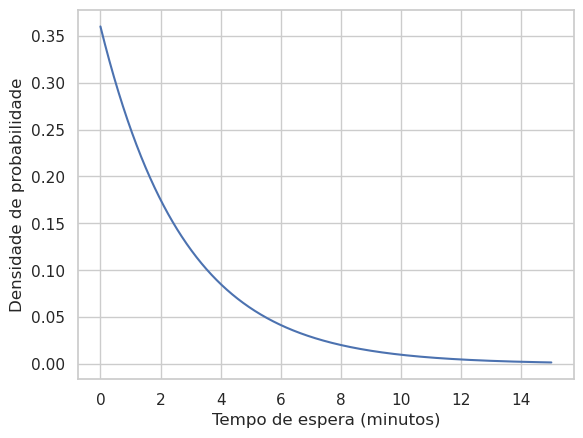

In [12]:

eixo_x = np.linspace(0, 15, 1000)

eixo_y = expon.pdf(
    eixo_x,
    scale=media
)

sns.lineplot(x=eixo_x, y=eixo_y)

plt.xlabel("Tempo de espera (minutos)")
plt.ylabel("Densidade de probabilidade")
plt.show()

Vejamos agora o gráfico da probabilidade acumulada.

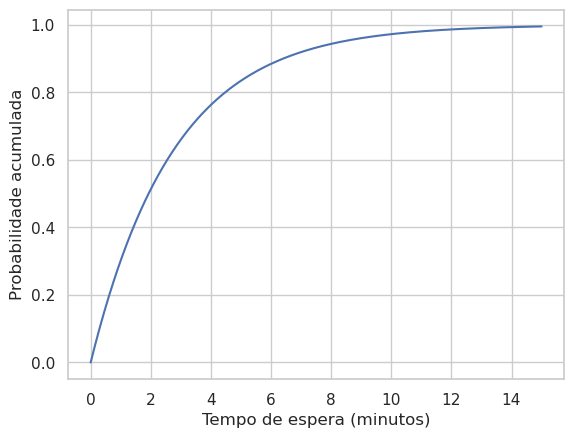

In [13]:

eixo_y = expon.cdf(
    eixo_x,
    scale=media
)

sns.lineplot(x=eixo_x, y=eixo_y)

plt.xlabel("Tempo de espera (minutos)")
plt.ylabel("Probabilidade acumulada")
plt.show()

Vamos utilizar os 1.000 tempos de espera simulados anteriormente para calcular a proporção de clientes que chegaram em menos de 5 minutos.

In [14]:
# Probabilidade teórica
p_teorica = expon.cdf(5, scale=media)

# Frequência relativa observada
p_simulada = np.mean(tempos < 5)

print(f"Probabilidade teórica: {p_teorica:.4f}")
print(f"Probabilidade simulada: {p_simulada:.4f}")

Probabilidade teórica: 0.8347
Probabilidade simulada: 0.8440


Agora, vamos repetir o experimento utilizando 100.000 valores.

In [15]:

tempos = np.random.exponential(
    scale=media,
    size=100000
)

p_simulada = np.mean(tempos < 5)

print(f"Probabilidade teórica: {p_teorica:.4f}")
print(f"Probabilidade simulada: {p_simulada:.4f}")

Probabilidade teórica: 0.8347
Probabilidade simulada: 0.8365


### Exercício 1
Uma central telefônica recebe, em média, 6 chamadas por hora. Considere que as chamadas seguem um processo de Poisson homogêneo.

a) Qual é o tempo médio de espera entre duas chamadas consecutivas?

b) Qual é a probabilidade de que a próxima chamada ocorra em menos de 5 minutos?

c) Qual é a probabilidade de que o tempo de espera ultrapasse 15 minutos?

In [16]:
#A
lamb = 6/60
media = 1/lamb
print(media)

10.0


In [17]:
#B
print(expon.cdf(5, scale=media))

0.3934693402873666


In [18]:
#C
print(expon.sf(15, scale=media))

0.22313016014842982


### Exercício 2
O tempo de resposta de determinado serviço segue uma distribuição Exponencial com média de 200 milissegundos.

a) Qual é o valor do parâmetro λ, considerando o tempo em milissegundos?

b) Qual é a probabilidade de que uma requisição seja respondida em menos de 100 milissegundos?

c) Qual é a probabilidade de que o tempo de resposta esteja entre 100 e 300 milissegundos?

d) Construa um gráfico da função densidade de probabilidade.

In [19]:
#A
# 1/lamb = 200 -> lamb = 1/200
print(1/200)

0.005


In [20]:
#B
expon.cdf(100, scale=200)

0.3934693402873666

In [21]:
#C
expon.cdf(300, scale=200) - expon.cdf(100, scale=200)

0.38340049956420363

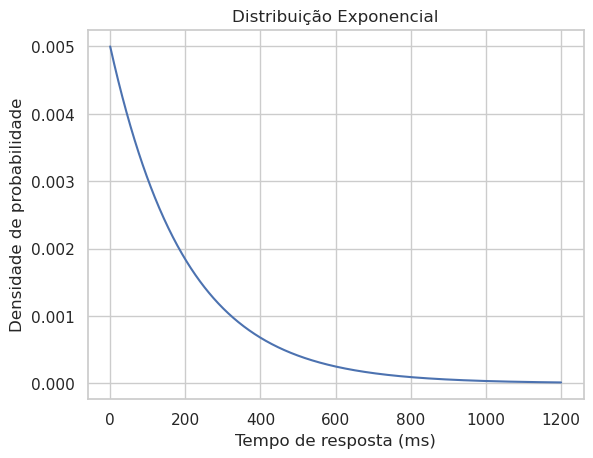

In [22]:
#D
media = 200
x = np.linspace(0, 1200, 1000)

y = expon.pdf(x, scale=media)

plt.plot(x, y)
plt.xlabel("Tempo de resposta (ms)")
plt.ylabel("Densidade de probabilidade")
plt.title("Distribuição Exponencial")
plt.grid(True)
plt.show()

### Exercício 3
Um sistema recebe, em média, 12 requisições por minuto, seguindo um processo de Poisson homogêneo.

a) Gere 10.000 tempos de espera entre requisições consecutivas.

b) Construa um histograma dos valores simulados.

c) Calcule a média e o desvio-padrão dos tempos simulados.

d) Compare os resultados obtidos com os valores teóricos da distribuição.

e) Calcule a proporção de tempos de espera inferiores a 3 segundos e compare com a probabilidade teórica.

In [23]:
#A
lamb = 12 / 60
media = 1 / lamb

rng = np.random.default_rng(42)

tempos = rng.exponential(
    scale=media,
    size=10000
)

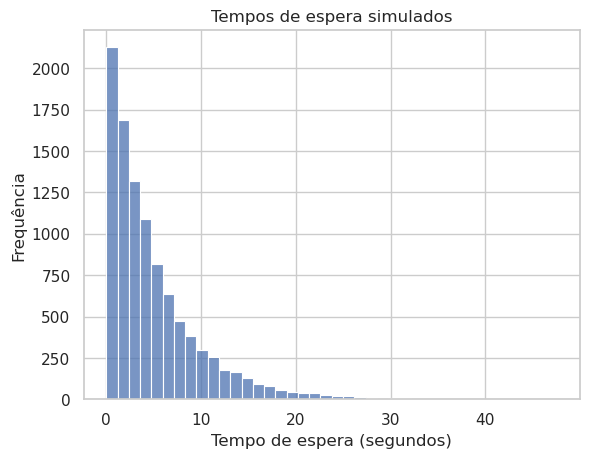

In [24]:
#B
sns.histplot(tempos, bins=40)

plt.xlabel("Tempo de espera (segundos)")
plt.ylabel("Frequência")
plt.title("Tempos de espera simulados")
plt.show()

In [25]:
#C
media_simulada = np.mean(tempos)
dp_simulado = np.std(tempos)

print(f"Média: {media_simulada:.4f}")
print(f"Desvio padrão: {dp_simulado:.4f}")

Média: 4.9435
Desvio padrão: 4.9624


In [26]:
#D
print("Média teórica:", media)
print("Média simulada:", media_simulada)

print("DP teórico:", media)
print("DP simulado:", dp_simulado)

Média teórica: 5.0
Média simulada: 4.943501977666662
DP teórico: 5.0
DP simulado: 4.962380534925503


In [27]:
#E

p_teorica = expon.cdf(3, scale=media)

p_simulada = np.mean(tempos < 3)

print(f"Teórica: {p_teorica:.5f}")
print(f"Simulada: {p_simulada:.5f}")

Teórica: 0.45119
Simulada: 0.45390


### Exercício 4
Um sistema recebe, em média, 4 requisições por minuto, seguindo um processo de Poisson homogêneo.

Determine o tempo máximo de espera t para o qual existe uma probabilidade de 95% de que a próxima requisição ocorra até esse instante.

Construa um gráfico da distribuição, indicando o tempo encontrado.

In [28]:
lamb = 4
media = 1 / lamb

t = expon.ppf(0.95, scale=media)

print(f"Tempo em minutos: {t:.5f}")
print(f"Tempo em segundos: {t * 60:.2f}")

Tempo em minutos: 0.74893
Tempo em segundos: 44.94


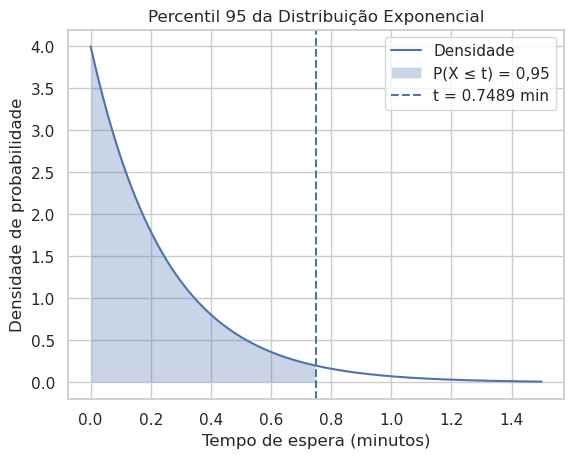

In [29]:
x = np.linspace(0, 1.5, 1000)
y = expon.pdf(x, scale=media)

plt.plot(x, y, label="Densidade")

# Destacar a região correspondente a 95%
plt.fill_between(
    x, y,
    where=(x <= t),
    alpha=0.3,
    label="P(X ≤ t) = 0,95"
)

plt.axvline(
    t,
    linestyle="--",
    label=f"t = {t:.4f} min"
)

plt.xlabel("Tempo de espera (minutos)")
plt.ylabel("Densidade de probabilidade")
plt.title("Percentil 95 da Distribuição Exponencial")

plt.legend()
plt.grid(True)
plt.show()